In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [ ]:
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True' # Error solving

In [3]:
#GPU/CPU 선택
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [4]:
#데이터셋 경로설정
celeba_dir = './data/'

In [5]:
#데이터셋 클래스 정의
class CelebADataset(Dataset):
    def __init__(self, img_dir, transform=None):
        self.img_dir = img_dir
        self.transform = transform
        # 이미지 파일만 필터링 (숨겨진 파일과 비이미지 파일 제외)
        valid_extensions = {'.jpg', '.jpeg', '.png', '.gif', '.bmp', '.tiff'}
        self.img_names = [f for f in os.listdir(img_dir) 
                         if not f.startswith('.') and 
                            os.path.splitext(f)[1].lower() in valid_extensions]
        
    def __len__(self):
        return len(self.img_names)
    
    def __getitem__(self, idx):
        img_name = os.path.join(self.img_dir, self.img_names[idx])
        image = Image.open(img_name).convert('RGB')   # 이미지를 rgb형식으로 변환
        if self.transform:
            image = self.transform(image)
        return image

In [27]:
#데이터 전처리
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [28]:
celeba_data = CelebADataset(img_dir=celeba_dir, transform=transform)
data_loader = DataLoader(dataset=celeba_data, batch_size=64, shuffle=True)

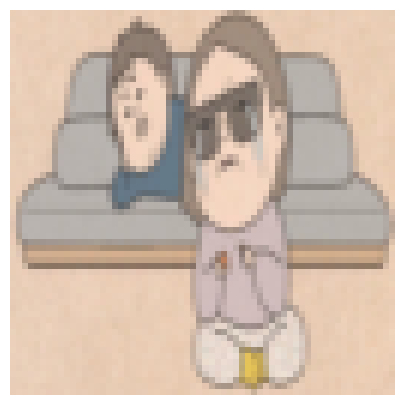

In [ ]:
# 데이터셋에서 첫 번째 이미지 시각화 (RGB 채널을 마지막으로 변환)
img = celeba_data[0]  # shape: (3, 64, 64)

plt.figure(figsize=(5, 5))
plt.imshow(img.permute(1, 2, 0))  # shape: (64, 64, 3)
plt.axis('off')
plt.show()

In [30]:
class VAE(nn.Module):
    def __init__(self, input_channels, hidden_dim, latent_dim):
        super(VAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=4, stride=2, padding=1),
            nn.ReLU()
        )
        self.fc1 = nn.Linear(256*4*4, latent_dim) # 평균
        self.fc2 = nn.Linear(256*4*4, latent_dim) # 분산
        self.fc3 = nn.Linear(latent_dim, 256*4*4)
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, input_channels, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )
        
    def encode(self, x):
        h = self.encoder(x)
        h = h.view(h.size(0), -1)
        return self.fc1(h), self.fc2(h)
    
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        h = self.fc3(z)
        h = h.view(h.size(0), 256, 4, 4)
        return self.decoder(h)
    
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

In [31]:
def loss_function_MSE(recon_x, x, mu, logvar):
    MSE = nn.functional.mse_loss(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE+KLD

In [32]:
def show_images(images):
    fig, axes = plt.subplots(1, len(images), figsize=(len(images)*2,2))
    for img, ax in zip(images, axes):
        ax.imshow(img)
        ax.axis('off')
    plt.show()

In [33]:
def interpolate_latent_space(model, start, end, steps=10):
    vectors = []
    alpha_values = np.linspace(0,1,steps)
    for alpha in alpha_values:
        vec = (1-alpha) * start + alpha * end
        vectors.append(vec)
    vectors = torch.stack(vectors)
    return vectors

In [34]:
model = VAE(input_channels = 3, hidden_dim=400, latent_dim=100).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [35]:
def train(epoch, loss_fn):
    model.train()
    train_loss = 0
    for batch_idx, data in enumerate(data_loader):
        data = data.to(device)
        optimizer.zero_grad()
        recon_batch, mu, logvar = model(data)
        loss = loss_fn(recon_batch, data, mu, logvar)
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
    print(f'Epoch {epoch}, Loss: {train_loss / len(data_loader.dataset)}')

In [36]:
loss_fn = loss_function_MSE

for epoch in range(1,11):
    train(epoch, loss_fn)

Epoch 1, Loss: 744.26513671875
Epoch 2, Loss: 726.9174194335938
Epoch 3, Loss: 706.4304809570312
Epoch 4, Loss: 679.7049560546875
Epoch 5, Loss: 611.1474609375
Epoch 6, Loss: 520.2521362304688
Epoch 7, Loss: 471.375244140625
Epoch 8, Loss: 499.66302490234375
Epoch 9, Loss: 368.4191589355469
Epoch 10, Loss: 321.66229248046875


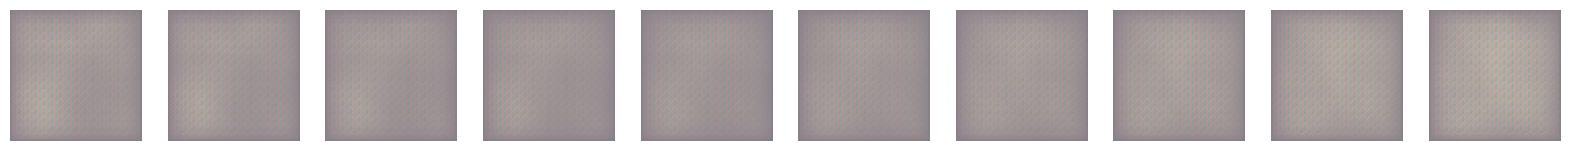

In [37]:
# 두 랜덤 벡터 사이를 보간하여 다양한 스타일의 얼굴 이미지를 생성...
steps = 10
with torch.no_grad():
    z_start = torch.randn(1, 100).to(device)
    z_end = torch.randn(1, 100).to(device)
    interpolated_z = interpolate_latent_space(model, z_start, z_end)
    samples = model.decode(interpolated_z).cpu()
    samples = samples.permute(0,2,3,1).numpy()
    show_images([samples[i] for i in range(steps)])
    torch.cuda.empty_cache()